1.1 Linear Regression Using pure math !

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib
import kagglehub
import pandas as pd

d:\practice_coding\uv-venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
folder_path_variable = pathlib.Path("Data")
folder_path_variable.mkdir(exist_ok=True)

In [3]:
kagglehub.dataset_download("krishnaraj30/salary-prediction-data-simple-linear-regression", output_dir='folder_path_variable', force_download=True)

100%|██████████| 734/734 [00:00<00:00, 735kB/s]

Extracting files...


'folder_path_variable'

In [4]:
data = pd.read_csv(folder_path_variable / 'Salary_Data.csv')

In [5]:
data.shape

(30, 2)

In [6]:
data.head(5)

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


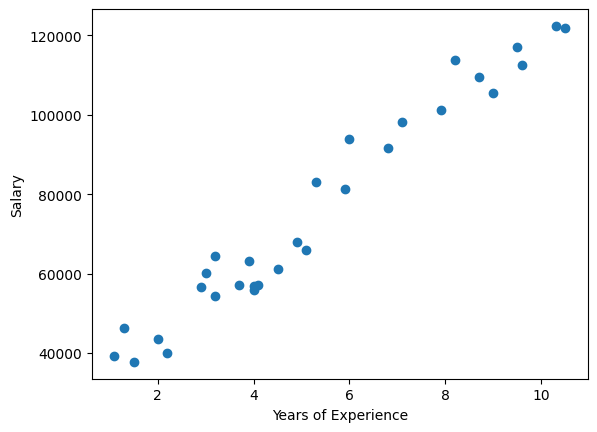

In [7]:
X = data['YearsExperience']
y = data['Salary']

plt.scatter(X,y)
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.plot()
plt.show()

In [8]:
def MSE_loss_function(X, y, w, b):
    m = len(X)
    total_loss = 0
    for i in range (m):
        loss = ((w*X[i] + b) - y[i])**2
        total_loss+=loss
    loss = (1/(2*m))*total_loss
    return loss
        


In [9]:
def gradient_descent_function(X, y, b, w):
    dw_sum = 0
    db_sum = 0
    m = len(X)
    for i in range(m):
        dc_dw = X[i]*((w*X[i]+b)-y[i])
        dw_sum += dc_dw
        dc_db =  (w*X[i]+b)-y[i]
        db_sum += dc_db
    dw = dw_sum/m
    db = db_sum/m
    return dw, db


In [10]:
import random
random.seed(42)
def gradient_update(X, y, iterations, alpha): # the X and y are passed to both gradient_descent_function and MSE_loss_function
    w = np.random.random()
    b = 0
    for i in range(iterations):
        dw, db = gradient_descent_function(X, y, b, w) 
        w = w - alpha*dw
        b = b - alpha*db
        loss = MSE_loss_function(X, y, w, b)
        print(f'Total loss: {loss}')
    return w, b

In [11]:
final_w, final_b = gradient_update(X, y, iterations = 10000, alpha = 0.01)

Total loss: 1344465689.1087246
Total loss: 582875342.0038267
Total loss: 278572886.4992187
Total loss: 156893116.27389023
Total loss: 108146008.08417842
Total loss: 88525861.84757704
Total loss: 80538474.51150519
Total loss: 77197376.01957087
Total loss: 75712454.00552176
Total loss: 74969449.30018832
Total loss: 74523369.79270346
Total loss: 74196501.20269227
Total loss: 73917869.06660452
Total loss: 73659126.43802989
Total loss: 73408950.06414413
Total loss: 73162815.2684446
Total loss: 72918912.4581594
Total loss: 72676516.34470627
Total loss: 72435334.67716944
Total loss: 72195248.15310927
Total loss: 71956206.54955831
Total loss: 71718187.24195419
Total loss: 71481178.63825658
Total loss: 71245173.56316648
Total loss: 71010166.61600947
Total loss: 70776153.11553681
Total loss: 70543128.67847736
Total loss: 70311089.05118297
Total loss: 70080030.04235014
Total loss: 69849947.49610665
Total loss: 69620837.28121932
Total loss: 69392695.28673954
Total loss: 69165517.42022005
Total los

In [12]:
final_w, final_b

(np.float64(9449.96232370979), np.float64(25792.20018347478))

In [13]:
X_new_list = np.arange(X.min(), X.max())
y_new_list = final_w * X_new_list + final_b

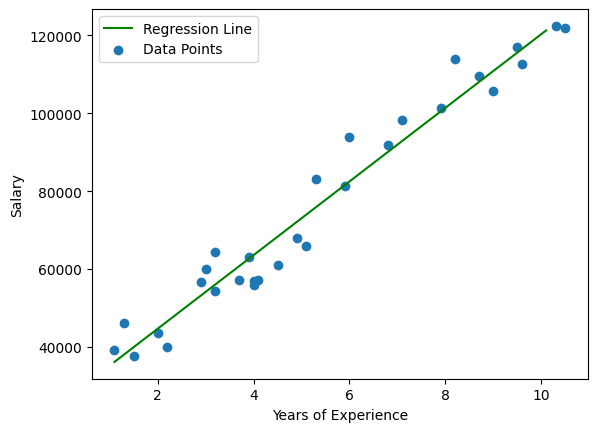

In [14]:
plt.plot(X_new_list, y_new_list, label='Regression Line', color ='Green')
plt.scatter(X, y, label = 'Data Points')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.plot()
plt.show()

1.2 Linear Regression using pytorch

In [77]:
import torch
from torch import nn

In [380]:
# Parameters to estimate
w = 3.23
b = 4.5

# Making values
independent_variable = torch.arange(1, 25, 0.50)
dependent_variable = w * independent_variable + b

X = independent_variable
y = dependent_variable

len(X),len(y)


(48, 48)

In [381]:
y

tensor([ 7.7300,  9.3450, 10.9600, 12.5750, 14.1900, 15.8050, 17.4200, 19.0350,
        20.6500, 22.2650, 23.8800, 25.4950, 27.1100, 28.7250, 30.3400, 31.9550,
        33.5700, 35.1850, 36.8000, 38.4150, 40.0300, 41.6450, 43.2600, 44.8750,
        46.4900, 48.1050, 49.7200, 51.3350, 52.9500, 54.5650, 56.1800, 57.7950,
        59.4100, 61.0250, 62.6400, 64.2550, 65.8700, 67.4850, 69.1000, 70.7150,
        72.3300, 73.9450, 75.5600, 77.1750, 78.7900, 80.4050, 82.0200, 83.6350])

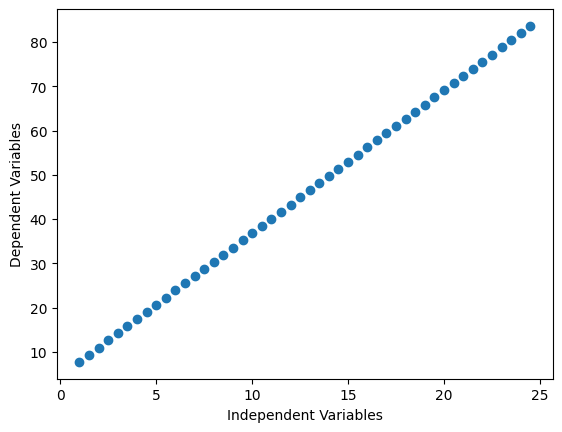

In [382]:
# Plotting Independent Varibales vs Dependent Variables

import matplotlib.pyplot as plt
plt.scatter(X, y, label='samples')
plt.xlabel("Independent Variables")
plt.ylabel("Dependent Variables")
plt.show()

In [383]:
import sklearn
from sklearn.model_selection import train_test_split

In [384]:
# Splitting data into train and test set

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

In [385]:
X_train.size(), y_train.size(), X_test.size(), y_test.size()

(torch.Size([38]), torch.Size([38]), torch.Size([10]), torch.Size([10]))

In [386]:
X_train = X_train.unsqueeze(dim=1)
X_test = X_test.unsqueeze(dim=1)
y_train = y_train.unsqueeze(dim=1)
y_test = y_test.unsqueeze(dim=1)

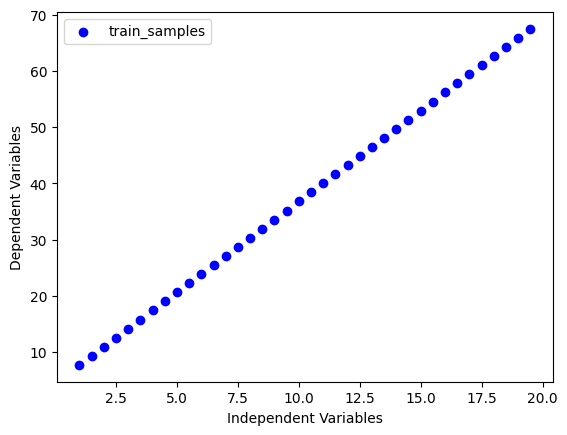

In [387]:
plt.scatter(X_train, y_train, label='train_samples', color = 'blue')
plt.xlabel("Independent Variables")
plt.ylabel("Dependent Variables")
plt.legend()
plt.show()

In [388]:
class Linear_Regression_Model(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(in_features=1, out_features=1)

    def forward(self, x):
        x = self.layer1(x)
        return x

torch.manual_seed(42)
LR_Model = Linear_Regression_Model()

In [389]:
LR_Model.parameters
LR_Model.state_dict()

OrderedDict([('layer1.weight', tensor([[0.7645]])),
             ('layer1.bias', tensor([0.8300]))])

In [390]:
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(lr=0.1, params=LR_Model.parameters())

In [391]:
X_train.ndim

2

In [392]:
X_train.shape

torch.Size([38, 1])

In [393]:
torch.manual_seed(42)
epochs = 55

training_loss = []
testing_loss = []
epoch_count = []

for epoch in range(epochs):
    

    LR_Model.train()

    y_pred = LR_Model(X_train)
    train_loss = loss_fn(y_pred, y_train)
    training_loss.append(train_loss.detach().numpy())
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    LR_Model.eval()
    with torch.inference_mode():
        test_pred = LR_Model(X_test)
        test_loss = loss_fn(test_pred, y_test)
        testing_loss.append(test_loss.detach().numpy())


    if epoch % 1 == 0:
        epoch_count.append(epoch)
        print(f'Epoch: {epoch} | Train_Loss: {train_loss} | Test_Loss: {test_loss}')

Epoch: 0 | Train_Loss: 1020.3147583007812 | Test_Loss: 3170.150634765625
Epoch: 1 | Train_Loss: 941.9402465820312 | Test_Loss: 2913.57568359375
Epoch: 2 | Train_Loss: 866.7896728515625 | Test_Loss: 2668.342529296875
Epoch: 3 | Train_Loss: 794.9148559570312 | Test_Loss: 2434.60009765625
Epoch: 4 | Train_Loss: 726.3601684570312 | Test_Loss: 2212.4697265625
Epoch: 5 | Train_Loss: 661.16162109375 | Test_Loss: 2002.0419921875
Epoch: 6 | Train_Loss: 599.3465576171875 | Test_Loss: 1803.3726806640625
Epoch: 7 | Train_Loss: 540.9322509765625 | Test_Loss: 1616.4810791015625
Epoch: 8 | Train_Loss: 485.9255676269531 | Test_Loss: 1441.3489990234375
Epoch: 9 | Train_Loss: 434.3226623535156 | Test_Loss: 1277.917236328125
Epoch: 10 | Train_Loss: 386.107666015625 | Test_Loss: 1126.083740234375
Epoch: 11 | Train_Loss: 341.252685546875 | Test_Loss: 985.7029418945312
Epoch: 12 | Train_Loss: 299.71722412109375 | Test_Loss: 856.58447265625
Epoch: 13 | Train_Loss: 261.4477844238281 | Test_Loss: 738.491333007

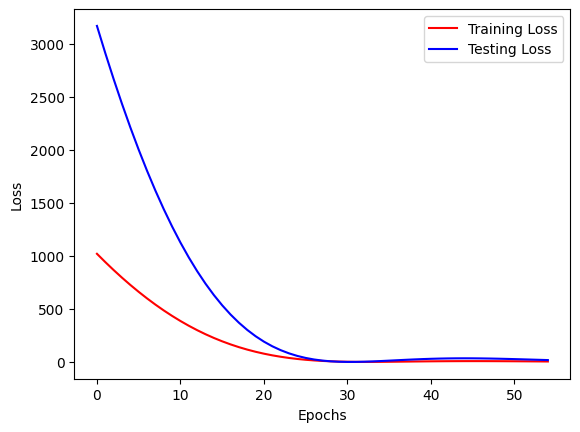

In [394]:
plt.plot(epoch_count, training_loss, label = 'Training Loss', color = 'red')
plt.plot(epoch_count, testing_loss, label = 'Testing Loss', color = 'blue')
plt.xlabel("Epochs")
plt.ylabel('Loss')
plt.legend()
plt.show()

In [395]:
print(LR_Model.state_dict())
print(LR_Model.state_dict().values())

OrderedDict([('layer1.weight', tensor([[3.4592]])), ('layer1.bias', tensor([3.5752]))])
odict_values([tensor([[3.4592]]), tensor([3.5752])])


In [396]:
LR_Model.eval()
with torch.inference_mode():
    y_preds = LR_Model(X_test)
y_preds

tensor([[72.7596],
        [74.4892],
        [76.2188],
        [77.9484],
        [79.6780],
        [81.4076],
        [83.1372],
        [84.8668],
        [86.5964],
        [88.3260]])

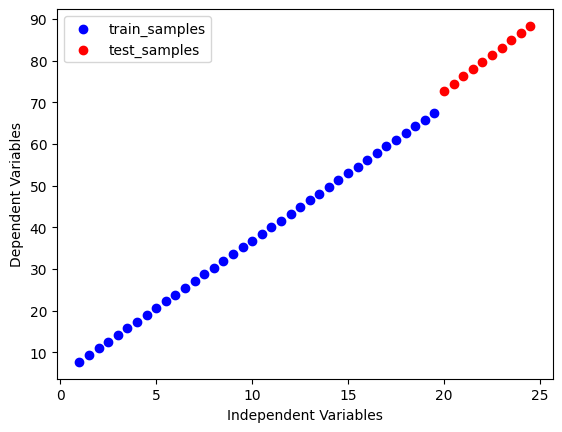

In [397]:
plt.scatter(X_train, y_train, label='train_samples', color = 'blue')
plt.scatter(X_test, y_preds, label='test_samples', color = 'red')
plt.xlabel("Independent Variables")
plt.ylabel("Dependent Variables")
plt.legend()
plt.show()

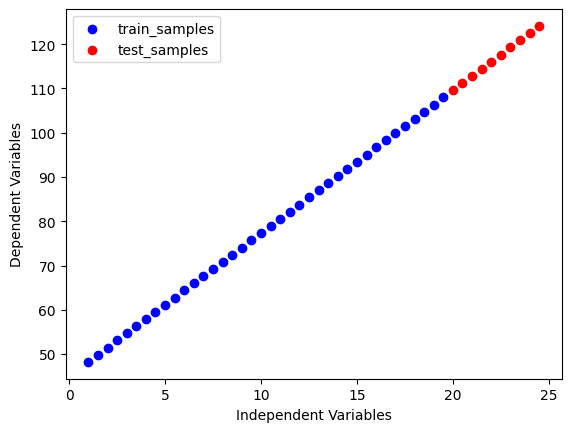

In [295]:
plt.scatter(X_train, y_train, label='train_samples', color = 'blue')
plt.scatter(X_test, y_test, label='test_samples', color = 'red')
plt.xlabel("Independent Variables")
plt.ylabel("Dependent Variables")
plt.legend()
plt.show()

In [412]:
# Saving Model

from pathlib import Path
model_path = pathlib.Path("Models")
model_path.mkdir(exist_ok=True)
model_name = "LR_Model.pth"
model_save_path = model_path/model_name
torch.save(LR_Model.state_dict(), model_save_path)

In [415]:
LR_Model_test = Linear_Regression_Model()
LR_Model_test.load_state_dict(torch.load(model_save_path, weights_only=True))

<All keys matched successfully>

In [417]:
LR_Model_test.eval()
with torch.inference_mode():
    LR_model_test_preds = LR_Model_test(X_test)
LR_model_test_preds == y_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

In [418]:
torch.allclose(LR_model_test_preds, y_preds, atol=1e-07)

True